# Collateral Liquidity Choice

## tl;dr
For the main synthetic balance sheet, a collateral-constrained mix uses less liquidation and lower private funding cost than liquidation-only. This is a one-bank optimization result—not a network equilibrium, policy recommendation, or welfare estimate.

## Context & Methods

The bank covers shortfall $g$ by selling $x$ units at terminal price $q(x)=\max(\underline q,q_0-a x)$ and borrowing $\ell=[g-q(x)x]^+$. Borrowing obeys $\ell\leq\theta q(x)(s-x)$. Private reduced-form cost is $(q_0-q(x))x+r\ell$.

### Key assumptions
One bank, one asset, simultaneous terminal-price proceeds, exogenous pledgeable fraction and borrowing rate, no default option, network, strategic lender, margin feedback, government, data, identification, or welfare function.

In [1]:
from pathlib import Path
import json, pandas as pd
import matplotlib.pyplot as plt
ROOT=Path.cwd()
main=pd.read_csv(ROOT/'results/main_results.csv')
sens=pd.read_csv(ROOT/'results/sensitivity.csv')
stability=pd.read_csv(ROOT/'results/stability.csv')
costs=pd.read_csv(ROOT/'results/costs.csv')
meta=json.loads((ROOT/'results/metadata.json').read_text())
print({'seed':meta['seed'],'random_cases':meta['random_cases'],'max_grid_cost_gap':meta['max_grid_cost_gap']})

{'seed': 20261022, 'random_cases': 50, 'max_grid_cost_gap': 9.21466337699961e-06}


## Results

The dense grid is an independent numerical baseline. Liquidation-only is the economic baseline.

In [2]:
main[['method','liquidation','borrowing','price','cost','collateral_slack']]

,method,liquidation,borrowing,price,cost,collateral_slack
0,collateral_choice,0.209839,0.212177,0.895081,0.043234,0.000000e+00
1,liquidation_only,0.552786,0.000000,0.723607,0.152786,9.708204e-02
2,dense_grid_200001,0.209840,0.212176,0.895080,0.043234,5.110400e-07


In [3]:
opt=main.query("method=='collateral_choice'").iloc[0]
pure=main.query("method=='liquidation_only'").iloc[0]
assert opt.cost < pure.cost and opt.borrowing > 0
print('relative private-cost reduction:', 1-opt.cost/pure.cost)

relative private-cost reduction: 0.7170305278659235


### Sensitivity and cost

Lines are deterministic scenarios, not confidence intervals. A lower private cost is not necessarily lower systemic cost.

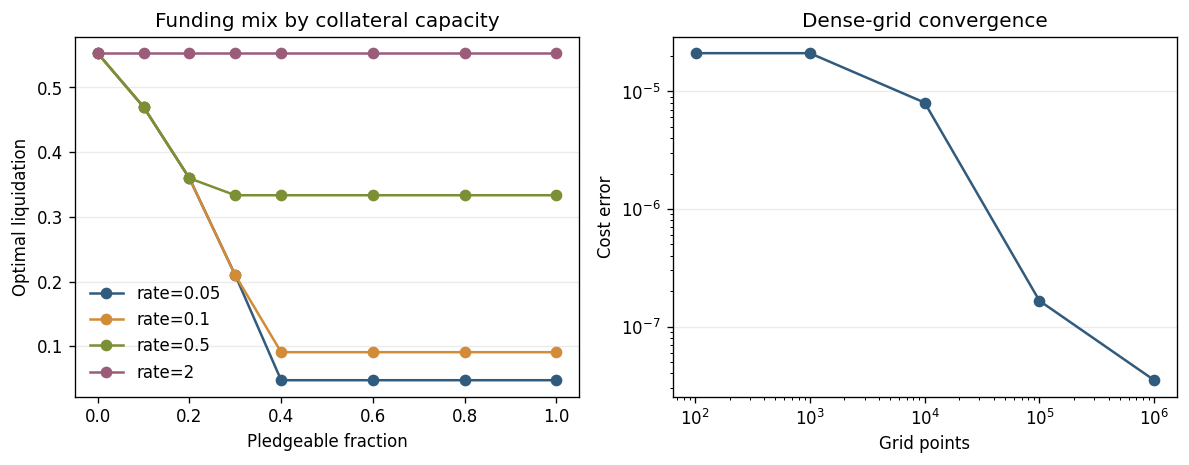

In [4]:
fig,axes=plt.subplots(1,2,figsize=(10,4))
palette={.05:'#315b7d',.1:'#d28b36',.5:'#7b8f35',2:'#9b5c7a'}
for rate,color in palette.items():
    sub=sens.query('rate == @rate').dropna()
    axes[0].plot(sub.pledgeable,sub.liquidation,marker='o',label=f'rate={rate:g}',color=color)
axes[0].set(xlabel='Pledgeable fraction',ylabel='Optimal liquidation',title='Funding mix by collateral capacity')
axes[0].legend(frameon=False)
axes[1].plot(stability.points,stability.cost_error,marker='o',color='#315b7d')
axes[1].set(xscale='log',yscale='log',xlabel='Grid points',ylabel='Cost error',title='Dense-grid convergence')
for ax in axes: ax.grid(axis='y',alpha=.25)
fig.tight_layout(); plt.show()

## Negative ablations

Abundant collateral alone still produces a mixed choice because positive-rate borrowing has a cost. Free borrowing selects borrowing-only; a high borrowing rate and zero price impact select liquidation. Hence “more collateral eliminates sales” is false under a positive funding price and this private objective.

In [5]:
pd.read_csv(ROOT/'results/ablations.csv')[['scenario','liquidation','borrowing','price','cost']]

,scenario,liquidation,borrowing,price,cost
0,abundant_collateral,0.090909,0.313223,0.954545,0.035455
1,free_borrowing,0.000000,0.400000,1.000000,0.000000
2,high_borrowing_rate,0.552786,0.000000,0.723607,0.152786
3,no_price_impact,0.400000,0.000000,1.000000,0.000000


## Takeaways

The candidate solver exposes the collateral boundary and agrees with dense grids while being much cheaper at scale. It advances a narrow S2 component; network equilibrium, strategic guarantees, empirical identification and welfare remain open.